# Softcite-style analysis of HAL software mentions

This notebook reproduces the spirit of the [`softcite/softcite-extractions-oa`](https://github.com/softcite/softcite-extractions-oa) analyses against software mentions extracted from HAL papers: the raw [Softcite `software-mentions`](https://github.com/softcite/software-mentions) output for the PEPR Santé Numérique corpus.

Softcite ships its dataset as **three tables** — `papers`, `mentions`, `purpose_assessments` — and demonstrates analyses on top of them. We rebuild those same three tables here as in-memory **pandas DataFrames** by flattening the raw JSON, then run an exploratory analysis.

**Scope choices (locked in):**
- We use the Softcite output files (`*.software.json`). Most were run on the GROBID TEI and also carry bibliographic metadata (`biblio`).
- Tables stay **in memory** — no Parquet export.
- Sections 2–6 use the **explicit** mentions: software named in the text (Softcite `software-type` `software`, `component` or `environment`). Section 7 looks at the **implicit** ones (`software-type` `implicit`: "our code", "the scripts").

**Known limitation:** the raw Softcite output has no `published_year`, `genre`, or `license` — only `biblio` (title / authors / doi). So Softcite's *papers-per-year trend* example cannot be reproduced; we pivot to the dimensions that are present (software names, purpose × scope, language, publisher, version, URL, citations). See the final **Limitations** section.

> **Hackathon note.** This notebook comes from [Inria-Datalake/analysis-notebooks](https://github.com/Inria-Datalake/analysis-notebooks), adapted to the PEPR Santé Numérique corpus.
>
> **Input:** the Softcite `software-mentions` output for the PEPR corpus, which is already on 🤗 [`HackatonSanteNumerique/pepr-hal-data`](https://huggingface.co/datasets/HackatonSanteNumerique/pepr-hal-data) in `softcite/`. Download it first (about 12 MB):
>
> ```bash
> uv run python scripts/download_pepr.py --pattern "softcite/*"
> ```
>
> The notebook then reads `data/pepr-hal-data/softcite/*.software.json`: 265 papers, 211 of them with at least one explicit software mention and 122 with an implicit one.
>
> The same three tables (`papers`, `mentions`, `purpose_assessments`) can be built from other extractors (CoPaLink, Baguette…) if you map their output to the schema below. That's a good way to compare models.

## 0 — Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Softcite output lives in <repo>/data/pepr-hal-data/softcite; this notebook lives in notebooks/.
# Resolve it whether the kernel runs from notebooks/ or the repo root.
DATA_DIR = Path("data/pepr-hal-data/softcite")
if not DATA_DIR.exists():
    DATA_DIR = Path("../data/pepr-hal-data/softcite")
assert DATA_DIR.exists(), (
    "Could not find data/pepr-hal-data/softcite/ — run: uv run python scripts/download_pepr.py --pattern 'softcite/*'"
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Data directory:", DATA_DIR.resolve())

Data directory: /data/workspace/lfoppiano/inria/hackaton-sante-numerique-2026/data/pepr-hal-data/softcite


## 1 — Load &amp; flatten into the three Softcite tables

Each `*.software.json` file looks like:

```jsonc
{
  "id": "<hash>",
  "biblio": { "title": ..., "authors": ..., "doi": ... },   // optional
  "mentions": [
    {
      "software-name": { "rawForm": ..., "normalizedForm": ... },
      "version":   { "rawForm": ..., "normalizedForm": ... },  // optional
      "publisher": { ... },                                    // optional
      "language":  { ..., "wikidataId": ... },                 // optional
      "url":       { ... },                                    // optional
      "references": [ ... ],                                   // citation links, optional
      "context": "... surrounding sentence ...",
      "mentionContextAttributes":  { "used": {value, score}, "created": {...}, "shared": {...} },
      "documentContextAttributes": { "used": {value, score}, "created": {...}, "shared": {...} }
    }
  ]
}
```

We map it to:
- **papers** — one row per file.
- **mentions** — one row per mention.
- **purpose_assessments** — exactly **6 rows per mention**: scope `{local, document}` × purpose `{used, created, shared}`.

In [2]:
files = sorted(DATA_DIR.glob("*.software.json"))
print(f"Found {len(files)} Softcite files")

records = []
for f in files:
    with open(f, encoding="utf-8") as fh:
        records.append((f, json.load(fh)))

Found 265 Softcite files


In [3]:
def field(mention, key):
    """Return (raw, normalized) for an optional sub-object like version/publisher/url."""
    obj = mention.get(key) or {}
    return obj.get("rawForm"), obj.get("normalizedForm")


# --- papers table ---------------------------------------------------------
paper_rows = []
for f, d in records:
    paper_id = d.get("id") or f.name.replace(".software.json", "")
    biblio = d.get("biblio") or {}
    mentions = d.get("mentions", [])
    paper_rows.append({
        "paper_id": paper_id,
        "title": biblio.get("title"),
        "authors": biblio.get("authors"),
        "doi": biblio.get("doi"),
        "source_file_type": "tei",
        "n_mentions": len(mentions),
        "has_mentions": len(mentions) > 0,
        "file_name": f.name,
    })

papers = pd.DataFrame(paper_rows)
papers.head()

,paper_id,title,authors,doi,source_file_type,n_mentions,has_mentions,file_name
0,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,A Blockchain-Enhanced Reversible Watermarking ...,"Reda Bellafqira, Chloé Berton, Gouenou Coatrieux",10.1109/csp66295.2025.00016,tei,11,True,ABlockchainEnhancedReversibleWatermarkingFrame...
1,857559d553177a7f858abc48047c6f04209429e6,AI for Computational Biology: Highlights from ...,"M Ahmad, Michał Denkiewicz, Rishika Gupta, Sac...",NaN,tei,116,True,AIforComputationalBiologyHighlightsfromthefirs...
2,18fe244c5272cf018591691ea078a27ab937594f,A Standards-Based Knowledge Graph that Bridges...,"Marie Schmit, Ulysse Le Clanche, George Marchm...",NaN,tei,376,True,AStandardsBasedKnowledgeGraphthatBridgesScient...
3,ffecb02ef212e3593981ae9bb28d5a16ca1c4b86,A Survey on Multimodal Federated Learning,"Silvia Grosso, Nawel Benarba, Sara Bouchenak, ...",NaN,tei,49,True,ASurveyonMultimodalFederatedLearning.software....
4,72bd546fbc5c44c0be94925d3ac67eff54c9171c,NaN,NaN,NaN,tei,2,True,AWhiteBoxWatermarkingModulationforEncryptedDNN...


### The key reshape: melting purpose assessments

Softcite's `purpose_assessments` table is **tidy**: exactly six rows per mention, one for each `(scope, purpose)` pair, each with a boolean `value` and a `certainty_score`. Our raw JSON stores those same six numbers as **two nested blocks**:

| raw block | becomes `scope` |
|---|---|
| `mentionContextAttributes`  | `"local"`    |
| `documentContextAttributes` | `"document"` |

So tidying the data is a pure **unpivot (melt)**: nested-wide → long. No information is created or lost — just reshaped.

`melt_purposes` below does exactly this — a double loop over the two scopes and three purposes, returning a list of **6 dicts** with keys `software_mention_id`, `paper_id`, `mention_index`, `scope`, `purpose`, `value`, `certainty_score`. Two choices are baked in:

- The scope naming (`local` vs `document`) is the contract every later analysis depends on — Softcite's headline query filters `scope == "document"`.
- A missing block or purpose defaults to `value=False`, `score=NaN`, so absent data never masquerades as a real `0.0`.

In [4]:
SCOPES = {"local": "mentionContextAttributes", "document": "documentContextAttributes"}
PURPOSES = ("used", "created", "shared")


def melt_purposes(mention, paper_id, mention_index):
    """Unpivot a mention's two attribute blocks into 6 tidy purpose-assessment rows.

    Returns a list of exactly len(SCOPES) * len(PURPOSES) == 6 dicts.
    """
    sid = f"{paper_id}:tei:{mention_index}"
    rows = []
    for scope, block_key in SCOPES.items():
        attrs = mention.get(block_key) or {}
        for purpose in PURPOSES:
            a = attrs.get(purpose) or {}
            rows.append({
                "software_mention_id": sid,
                "paper_id": paper_id,
                "mention_index": mention_index,
                "scope": scope,
                "purpose": purpose,
                "value": bool(a.get("value", False)),
                "certainty_score": float(a["score"]) if "score" in a else float("nan"),
            })
    return rows


# Show the target shape on the first mention available.
first_mention = next(m for _f, _d in records for m in _d.get("mentions", []))
pd.DataFrame(melt_purposes(first_mention, "DEMO", 0))

,software_mention_id,paper_id,mention_index,scope,purpose,value,certainty_score
0,DEMO:tei:0,DEMO,0,local,used,False,9.250641e-05
1,DEMO:tei:0,DEMO,0,local,created,False,5.209446e-05
2,DEMO:tei:0,DEMO,0,local,shared,False,2.384186e-07
3,DEMO:tei:0,DEMO,0,document,used,True,9.998484e-01
4,DEMO:tei:0,DEMO,0,document,created,False,1.341581e-03
5,DEMO:tei:0,DEMO,0,document,shared,False,3.576279e-07


In [5]:
# --- mentions & purpose_assessments tables --------------------------------
mention_rows = []
purpose_rows = []
for f, d in records:
    paper_id = d.get("id") or f.name.replace(".software.json", "")
    for i, m in enumerate(d.get("mentions", [])):
        name = m.get("software-name") or {}
        lang = m.get("language") or {}
        v_raw, v_norm = field(m, "version")
        p_raw, p_norm = field(m, "publisher")
        u_raw, u_norm = field(m, "url")
        mention_rows.append({
            "software_mention_id": f"{paper_id}:tei:{i}",
            "paper_id": paper_id,
            "mention_index": i,
            "software_raw": name.get("rawForm"),
            "software_normalized": name.get("normalizedForm"),
            "software_type": m.get("software-type"),
            "version_raw": v_raw,
            "version_normalized": v_norm,
            "publisher_raw": p_raw,
            "publisher_normalized": p_norm,
            "language_raw": lang.get("rawForm"),
            "language_normalized": lang.get("normalizedForm"),
            "language_wikidata": lang.get("wikidataId"),
            "url_raw": u_raw,
            "url_normalized": u_norm,
            "context_full_text": m.get("context"),
            "n_references": len(m.get("references") or []),
        })
        purpose_rows.extend(melt_purposes(m, paper_id, i))

mentions = pd.DataFrame(mention_rows)
purpose_assessments = pd.DataFrame(purpose_rows)
mentions.head()

,software_mention_id,paper_id,mention_index,software_raw,software_normalized,software_type,version_raw,version_normalized,publisher_raw,publisher_normalized,language_raw,language_normalized,language_wikidata,url_raw,url_normalized,context_full_text,n_references
0,9a6f42659f92bc42e55c72783fa433a1ce86e6b4:tei:0,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,0,Alg,Alg,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Alg. 2 ensures perfect reconstruction of the o...,0
1,9a6f42659f92bc42e55c72783fa433a1ce86e6b4:tei:1,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,1,VGG16 2,VGG16 2,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,We utilized the VGG16 2 architecture as our ba...,0
2,9a6f42659f92bc42e55c72783fa433a1ce86e6b4:tei:2,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,2,VGG16,VGG16,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,We utilized a pre-trained VGG16 network fine-t...,0
3,9a6f42659f92bc42e55c72783fa433a1ce86e6b4:tei:3,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,3,VGG16,VGG16,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,We trained two versions of the VGG16 model: i)...,0
4,9a6f42659f92bc42e55c72783fa433a1ce86e6b4:tei:4,9a6f42659f92bc42e55c72783fa433a1ce86e6b4,4,VGG16,VGG16,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Testing on a medical dataset using a VGG16 mod...,0


In [6]:
# --- sanity checks (the invariants Softcite's schema guarantees) ----------
print(f"papers:              {papers.shape}")
print(f"mentions:            {mentions.shape}")
print(f"purpose_assessments: {purpose_assessments.shape}")

assert len(purpose_assessments) == 6 * len(mentions), "expected exactly 6 purpose rows per mention"
assert mentions["software_mention_id"].is_unique, "software_mention_id must be unique"
per_mention = purpose_assessments.groupby("software_mention_id").size()
assert (per_mention == 6).all(), "every mention must have exactly 6 assessments"
print("\nAll invariants hold ✅")

papers:              (265, 8)
mentions:            (12115, 17)
purpose_assessments: (72690, 7)

All invariants hold ✅


### Explicit and implicit mentions

Softcite gives each mention a `software-type`:

- `software`, `component` (a plugin, a package) and `environment` (a programming language or environment): the software is **named** — these are the **explicit** mentions.
- `implicit`: the text refers to software without naming it ("our code", "the scripts", "a tool").

From here on, `mentions`, `purpose_assessments` and the counts in `papers` hold the **explicit** mentions only. The implicit ones are kept in `implicit_mentions` and `implicit_purposes` for section 7; `all_mentions` and `all_purpose_assessments` keep everything.

In [7]:
all_mentions, all_purpose_assessments = mentions, purpose_assessments
is_implicit = all_mentions["software_type"].eq("implicit")

implicit_mentions = all_mentions[is_implicit]
implicit_purposes = all_purpose_assessments[
    all_purpose_assessments["software_mention_id"].isin(implicit_mentions["software_mention_id"])]

# The analyses of sections 2–6 use the explicit mentions only.
mentions = all_mentions[~is_implicit]
purpose_assessments = all_purpose_assessments[
    all_purpose_assessments["software_mention_id"].isin(mentions["software_mention_id"])]

papers["n_mentions"] = papers["paper_id"].map(mentions.groupby("paper_id").size()).fillna(0).astype(int)
papers["has_mentions"] = papers["n_mentions"] > 0
papers["n_implicit"] = papers["paper_id"].map(implicit_mentions.groupby("paper_id").size()).fillna(0).astype(int)

print(all_mentions["software_type"].value_counts().to_string())
print(f"\nexplicit: {len(mentions)} mentions in {int(papers['has_mentions'].sum())} papers")
print(f"implicit: {len(implicit_mentions)} mentions in {int((papers['n_implicit'] > 0).sum())} papers")

software_type
software       11475
implicit         296
component        205
environment      139

explicit: 11819 mentions in 211 papers
implicit: 296 mentions in 122 papers


## 2 — Dataset overview

In [8]:
overview = pd.Series({
    "papers": len(papers),
    "papers with >=1 explicit mention": int(papers["has_mentions"].sum()),
    "papers with biblio (title)": int(papers["title"].notna().sum()),
    "papers with DOI": int(papers["doi"].notna().sum()),
    "explicit mentions": len(mentions),
    "distinct software (normalized)": mentions["software_normalized"].nunique(),
    "purpose assessments (explicit)": len(purpose_assessments),
    "implicit mentions (section 7)": len(implicit_mentions),
    "papers with >=1 implicit mention": int((papers["n_implicit"] > 0).sum()),
})
rate = papers["has_mentions"].mean()
print(overview.to_string())
print(f"\nShare of papers with at least one explicit software mention: {rate:.1%}")

papers                                265
papers with >=1 explicit mention      211
papers with biblio (title)            236
papers with DOI                       114
explicit mentions                   11819
distinct software (normalized)       1620
purpose assessments (explicit)      70914
implicit mentions (section 7)         296
papers with >=1 implicit mention      122

Share of papers with at least one explicit software mention: 79.6%


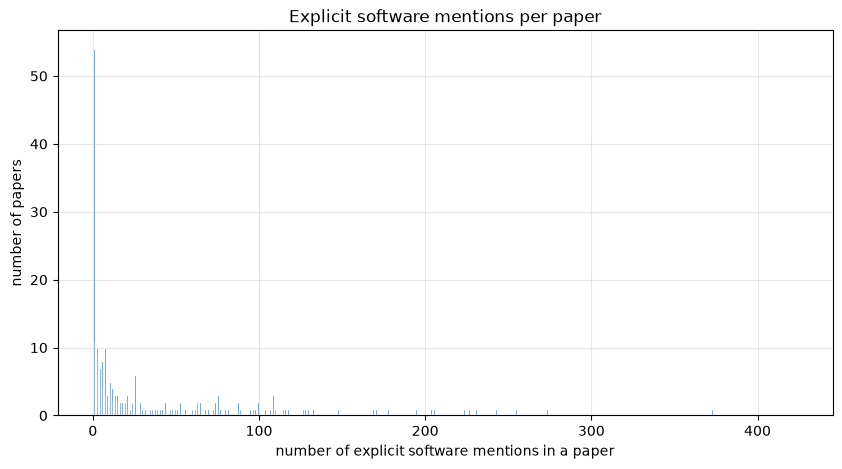

count    265.000000
mean      44.600000
std       65.682362
min        0.000000
25%        2.000000
50%       14.000000
75%       64.000000
max      423.000000


In [9]:
# Distribution of mentions per paper
ax = papers["n_mentions"].plot(kind="hist", bins=range(0, papers["n_mentions"].max() + 2),
                               edgecolor="white")
ax.set_title("Explicit software mentions per paper")
ax.set_xlabel("number of explicit software mentions in a paper")
ax.set_ylabel("number of papers")
plt.show()

print(papers["n_mentions"].describe().to_string())

## 3 — Top software

Mirrors Softcite example #1. We rank by the **normalized** name, which is less noisy than the raw form. Two complementary rankings: by raw mention count, and by *distinct papers* (a software mentioned many times in one paper shouldn't dominate).

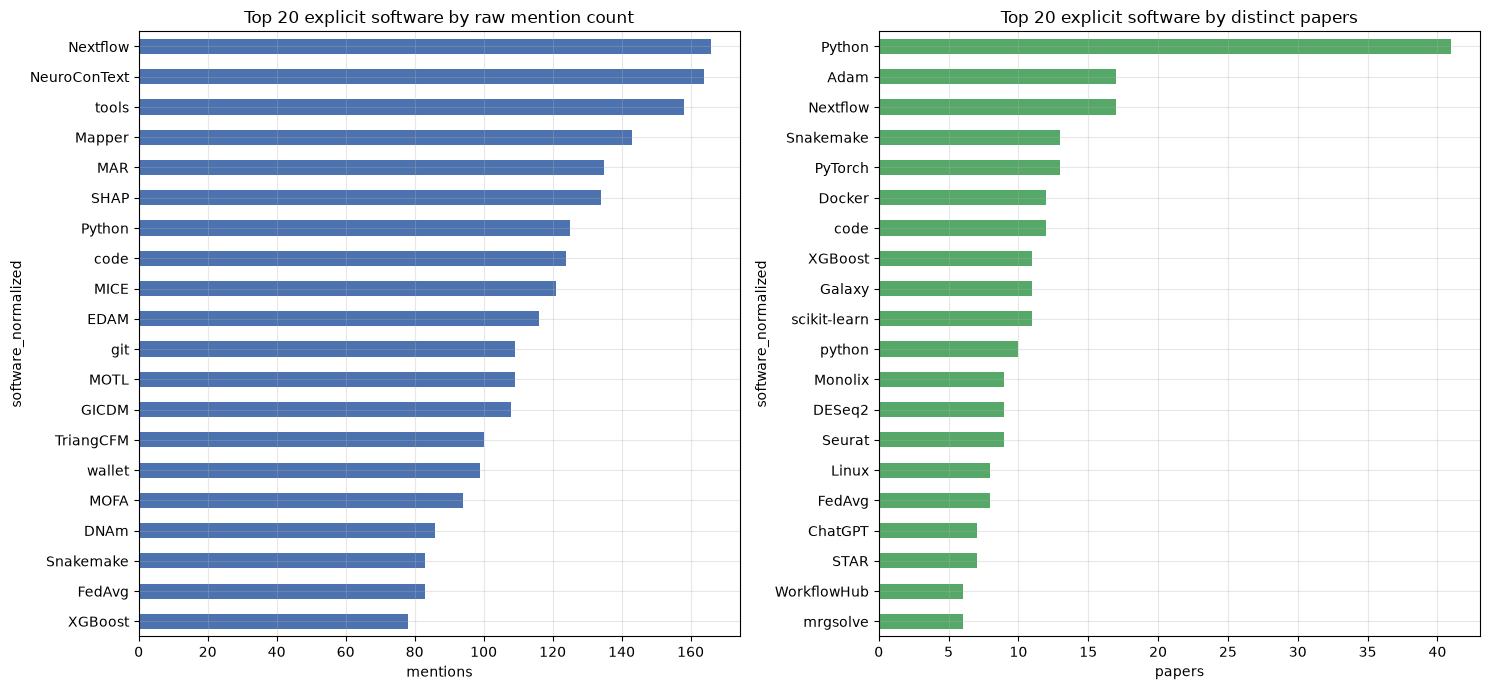

In [10]:
TOP_N = 20

by_mentions = mentions["software_normalized"].value_counts().head(TOP_N)
by_papers = (mentions.dropna(subset=["software_normalized"])
             .groupby("software_normalized")["paper_id"].nunique()
             .sort_values(ascending=False).head(TOP_N))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
by_mentions[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Top {TOP_N} explicit software by raw mention count")
axes[0].set_xlabel("mentions")
by_papers[::-1].plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title(f"Top {TOP_N} explicit software by distinct papers")
axes[1].set_xlabel("papers")
plt.tight_layout()
plt.show()

## 4 — Purpose × scope (the core analysis)

This mirrors Softcite example #3. Each mention is assessed on three purposes — was the software **used**, **created**, or **shared** — at two scopes:
- **local**: judged from the single mention's context only.
- **document**: judged using the whole paper.

Softcite's headline query uses `scope == "document"` because it asks about the *paper*, not an individual sentence.

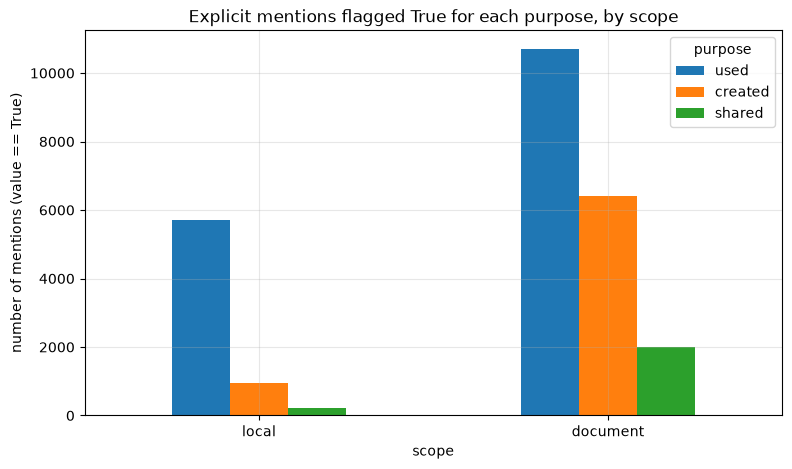

purpose,used,created,shared
scope,,,
local,5723,935,214
document,10707,6400,2009


In [11]:
# How often each purpose fires (value == True), at each scope
fired = (purpose_assessments[purpose_assessments["value"]]
         .groupby(["scope", "purpose"]).size().unstack("purpose")
         .reindex(index=["local", "document"], columns=list(PURPOSES)))

ax = fired.plot(kind="bar", figsize=(9, 5))
ax.set_title("Explicit mentions flagged True for each purpose, by scope")
ax.set_xlabel("scope")
ax.set_ylabel("number of mentions (value == True)")
ax.tick_params(axis="x", rotation=0)
plt.show()
fired

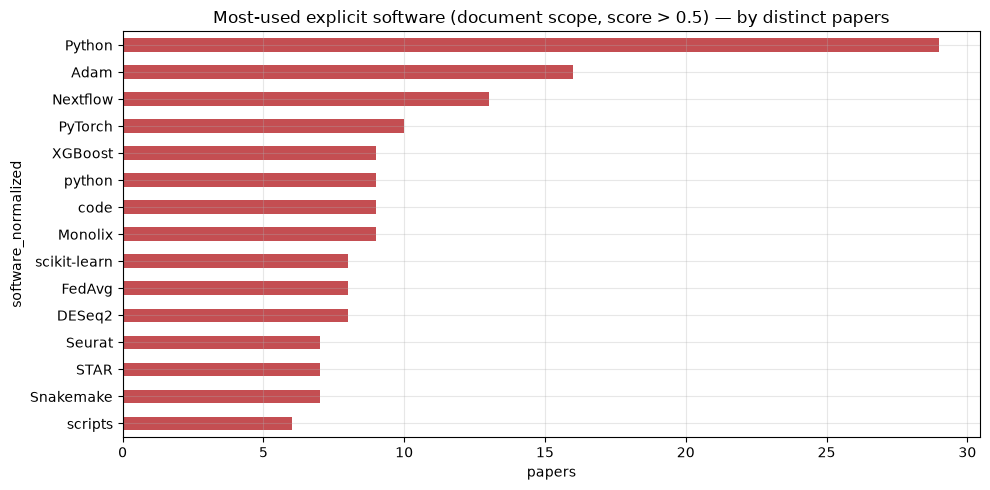

software_normalized
Python          29
Adam            16
Nextflow        13
PyTorch         10
XGBoost          9
python           9
code             9
Monolix          9
scikit-learn     8
FedAvg           8
DESeq2           8
Seurat           7
STAR             7
Snakemake        7
scripts          6
Name: paper_id, dtype: int64

In [12]:
def top_software_for(purpose, scope="document", min_score=0.5, top_n=15):
    """Distinct papers per software where the (scope, purpose) assessment is confident.

    Replicates Softcite example #3:  scope=='document', purpose=='used', score>0.5.
    """
    hits = purpose_assessments.query(
        "scope == @scope and purpose == @purpose and value and certainty_score > @min_score"
    )
    joined = hits.merge(mentions[["software_mention_id", "software_normalized"]],
                        on="software_mention_id", how="inner")
    return (joined.dropna(subset=["software_normalized"])
            .groupby("software_normalized")["paper_id"].nunique()
            .sort_values(ascending=False).head(top_n))


popular_used = top_software_for("used")
ax = popular_used[::-1].plot(kind="barh", color="#C44E52")
ax.set_title("Most-used explicit software (document scope, score > 0.5) — by distinct papers")
ax.set_xlabel("papers")
plt.tight_layout()
plt.show()
popular_used

In [13]:
# Software the papers' authors created, and software they shared
print("Top software CREATED (document scope, score > 0.5):")
print(top_software_for("created").to_string())
print("\nTop software SHARED (document scope, score > 0.5):")
print(top_software_for("shared").to_string() or "(none above threshold)")

Top software CREATED (document scope, score > 0.5):
software_normalized
Nextflow       12
Python         10
code            6
FedAvg          6
Snakemake       6
XGBoost         4
Galaxy          4
scripts         4
Hyperledger     3
BoNesis         3
PyTorch         3
Mapper          3
Docker          3
EDAM            3
tools           2

Top software SHARED (document scope, score > 0.5):
software_normalized
code            5
NeurIPS         4
Python          4
BoNesis         2
MultiQC         2
Nextflow        2
medkit          2
ktest           2
gitOmmix        2
Software        2
NeuroConText    2
NLStruct        2
Champollion     1
ChemoKG-open    1
ClinConNet      1


## 5 — Metadata richness

Beyond the name, each mention may carry a programming **language** (with a Wikidata id), a **publisher**, a **version**, a **URL**, and links to the paper's **citations**. How often is each present?

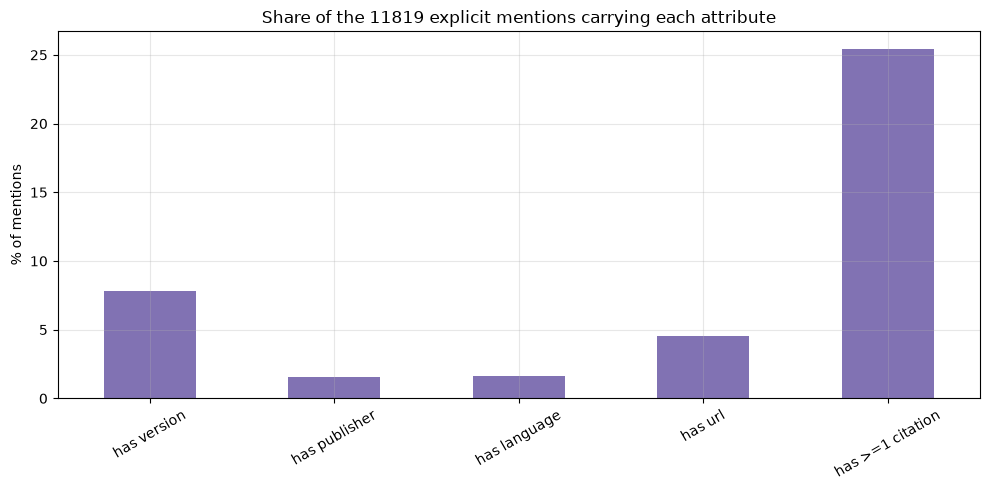

has version          7.8
has publisher        1.5
has language         1.6
has url              4.5
has >=1 citation    25.4
dtype: float64

In [14]:
n = len(mentions)
richness = pd.Series({
    "has version": mentions["version_normalized"].notna().mean(),
    "has publisher": mentions["publisher_normalized"].notna().mean(),
    "has language": mentions["language_normalized"].notna().mean(),
    "has url": mentions["url_normalized"].notna().mean(),
    "has >=1 citation": (mentions["n_references"] > 0).mean(),
})
ax = (richness * 100).plot(kind="bar", color="#8172B3")
ax.set_title(f"Share of the {n} explicit mentions carrying each attribute")
ax.set_ylabel("% of mentions")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
(richness * 100).round(1)

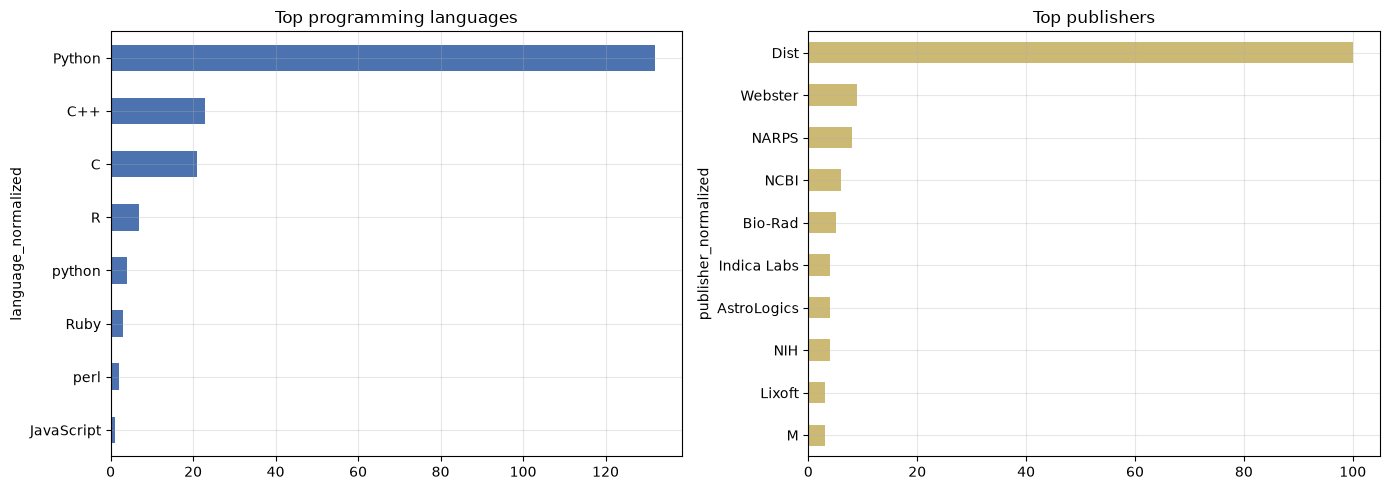

In [15]:
lang = mentions["language_normalized"].value_counts().head(10)
pub = mentions["publisher_normalized"].value_counts().head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lang[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Top programming languages")
pub[::-1].plot(kind="barh", ax=axes[1], color="#CCB974")
axes[1].set_title("Top publishers")
plt.tight_layout()
plt.show()

## 6 — Single-software deep dive

Mirrors Softcite example #1 ("how many papers mention X?"). Change `SOFTWARE` to any normalized name that appears in section 3.

In [16]:
# Default to the most-mentioned software so the cell always has something to show.
SOFTWARE = mentions["software_normalized"].value_counts().index[0]

sel = mentions[mentions["software_normalized"] == SOFTWARE]
print(f"Software: {SOFTWARE!r}")
print(f"  mentions:        {len(sel)}")
print(f"  distinct papers: {sel['paper_id'].nunique()}")
print("\nSample contexts:")
for ctx in sel["context_full_text"].dropna().head(3):
    print("  •", (ctx[:240] + "…") if len(ctx) > 240 else ctx)

Software: 'Nextflow'
  mentions:        166
  distinct papers: 17

Sample contexts:
  • First, Nextflow workflows metadata were generated using BioflowInsight [44].
  • Bioschemas Nextflow API Workflow RO-Crate Schema.org
  • Some of the Nextflow workflows are part of the nf-core    framework, while all galaxy workflows were taken from the Intergalactic Workflow Commission (IWC)    library.


## 7 — Implicit mentions

Implicit mentions refer to software without naming it: "the code is available on GitHub", "we wrote scripts". They matter for the *created* and *shared* questions — a paper that shares its own code often never names it.

Two views, as for the explicit software:

- **by mentions and by documents:** the words used, counted per mention and per distinct paper. Case is ignored (`Code` and `code` are one form).
- **by mention scope and document scope:** how often Softcite flags each purpose (used / created / shared) for these mentions, judged from the mention's own context (`local`) or from the whole paper (`document`).

296 implicit mentions in 122 papers (46.0% of the papers), 29 distinct forms


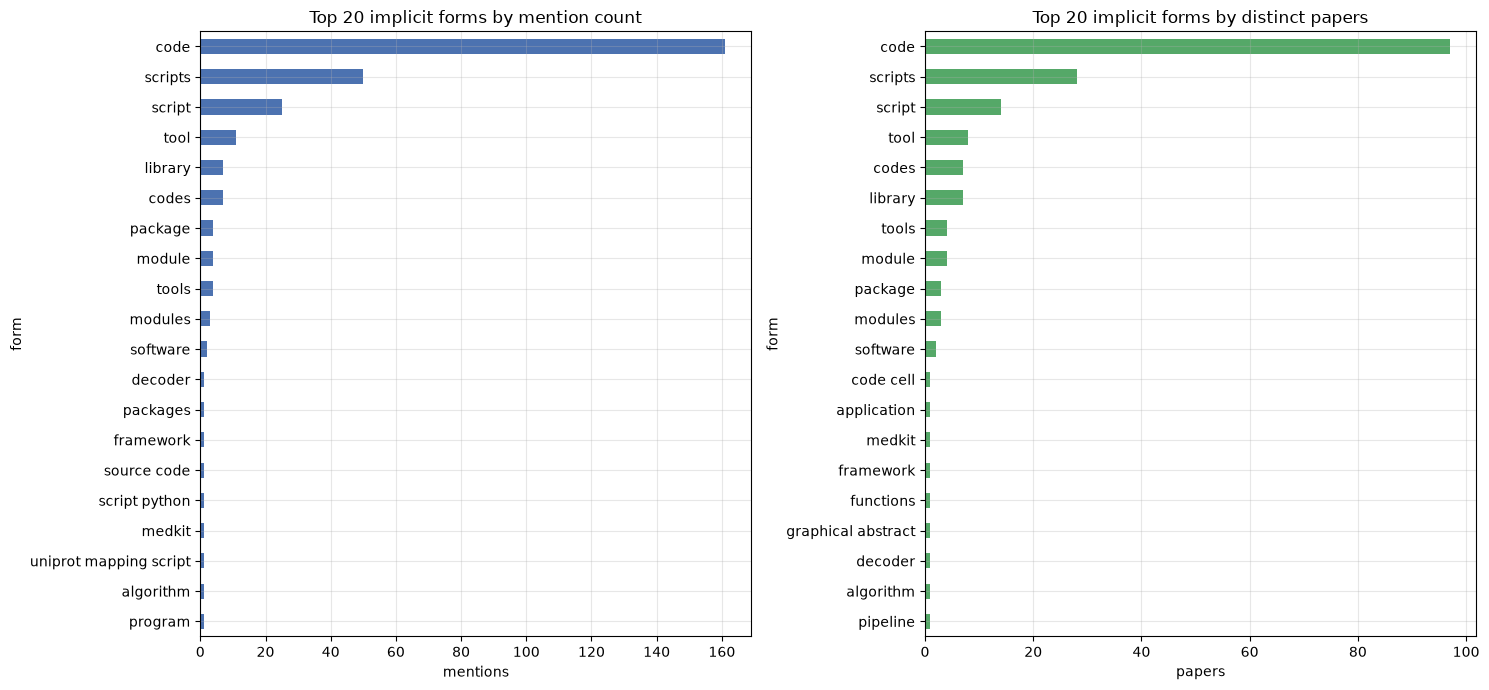

In [17]:
implicit_forms = implicit_mentions.assign(form=implicit_mentions["software_normalized"].str.lower().str.strip())

print(f"{len(implicit_mentions)} implicit mentions in {implicit_mentions['paper_id'].nunique()} papers "
      f"({implicit_mentions['paper_id'].nunique() / len(papers):.1%} of the papers), "
      f"{implicit_forms['form'].nunique()} distinct forms")

forms_by_mentions = implicit_forms["form"].value_counts().head(TOP_N)
forms_by_papers = (implicit_forms.groupby("form")["paper_id"].nunique()
                   .sort_values(ascending=False).head(TOP_N))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
forms_by_mentions[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Top {TOP_N} implicit forms by mention count")
axes[0].set_xlabel("mentions")
forms_by_papers[::-1].plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title(f"Top {TOP_N} implicit forms by distinct papers")
axes[1].set_xlabel("papers")
plt.tight_layout()
plt.show()

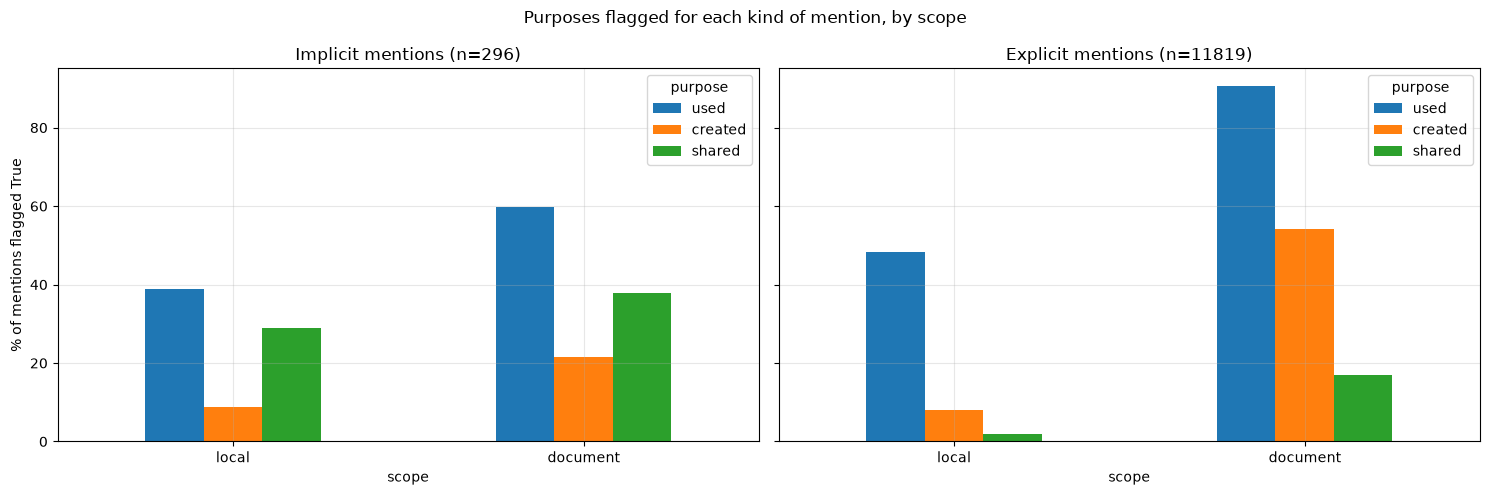

purpose,used,created,shared
scope,,,
local,115,26,86
document,177,64,112


In [18]:
# Purposes flagged True for the implicit mentions, at mention (local) and document scope
implicit_fired = (implicit_purposes[implicit_purposes["value"]]
                  .groupby(["scope", "purpose"]).size().unstack("purpose")
                  .reindex(index=["local", "document"], columns=list(PURPOSES)).fillna(0).astype(int))

# The same as a share, next to the explicit mentions, since there are far fewer implicit ones
def share_fired(assessments, n):
    return (assessments[assessments["value"]].groupby(["scope", "purpose"]).size() / n * 100).unstack("purpose") \
        .reindex(index=["local", "document"], columns=list(PURPOSES)).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
share_fired(implicit_purposes, len(implicit_mentions)).plot(kind="bar", ax=axes[0])
axes[0].set_title(f"Implicit mentions (n={len(implicit_mentions)})")
share_fired(purpose_assessments, len(mentions)).plot(kind="bar", ax=axes[1])
axes[1].set_title(f"Explicit mentions (n={len(mentions)})")
for ax in axes:
    ax.set_xlabel("scope")
    ax.set_ylabel("% of mentions flagged True")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Purposes flagged for each kind of mention, by scope")
plt.tight_layout()
plt.show()
implicit_fired

## 8 — Limitations

- **No publication year / genre / license.** The raw Softcite output carries only `biblio` (title, authors, doi), so Softcite's *papers-per-year trend* example and any genre/license breakdown are not reproducible from this data alone. Joining on DOI against an external metadata source (e.g. Crossref / OpenAlex) would be needed to recover publication dates.
- **Probabilistic extractions.** These mentions come from an ML model (Softcite reports f-scores around 0.8), so expect both false positives and false negatives. The `certainty_score` thresholds (e.g. `> 0.5`) trade recall for precision.
- **Explicit vs implicit.** The split relies on Softcite's `software-type`, which is itself a prediction. Implicit forms are generic words, so they say little about *which* software; read them for the purposes (created, shared) rather than the names.
- **Mixed inputs.** Most files come from the GROBID TEI (237 of the 265 have `biblio`); the others were run on plain text and have no bibliographic metadata, so their title, authors and DOI are empty.
- **Raw vs normalized names.** Rankings use `software_normalized`; some entries (e.g. generic words like `script`) are extraction noise rather than named software.